In [48]:
import numpy as np

n = 8

def generate_a_random_board():
    return np.random.randint(0, n, size=n)


def calculate_score(board):
    score = 0

    for i in range(n):
        for j in range(i + 1, n):
            if board[i] == board[j] or abs(board[i] - board[j]) == j - i:
                score += 1

    return score


def get_best_neighbour(board):
    best_score = float('inf')
    best_boards = []

    for col in range(n):
        original_row = board[col]

        for row in range(n):
            if row == original_row:
                continue

            board[col] = row
            score = calculate_score(board)

            if score < best_score:
                best_score = score
                best_boards = [board.copy()]

            elif score == best_score:
                best_boards.append(board.copy())

        board[col] = original_row

    return best_boards[np.random.randint(len(best_boards))]

Total trials: 100
Success rate: 91.00%

Successful runs
Count: 91
Mean: 18.01
Median: 12.00
Std Dev: 15.76
Min: 3
Max: 69

Failed runs
Count: 9
Mean: 78.67
Median: 100.00
Std Dev: 39.91
Min: 4
Max: 100

All runs
Count: 100
Mean: 23.47
Median: 12.50
Std Dev: 25.90
Min: 3
Max: 100


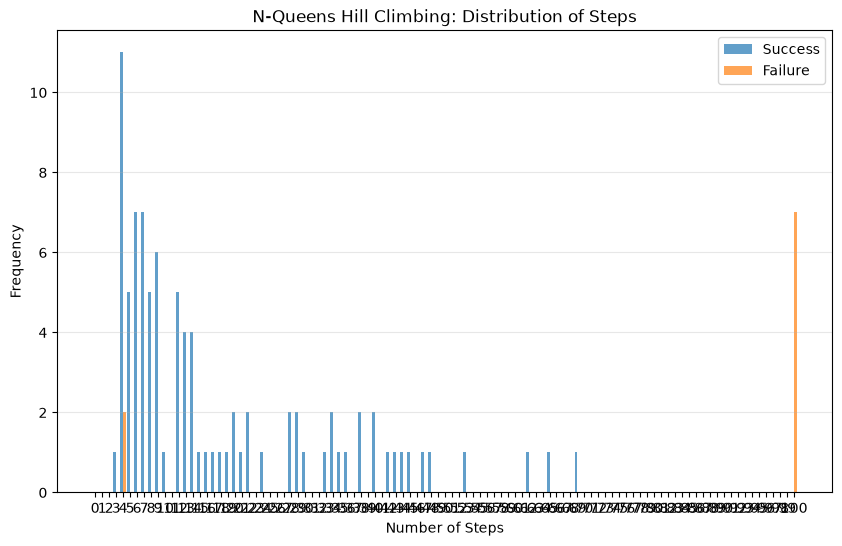

In [49]:
import numpy as np
import matplotlib.pyplot as plt

T = 100
STOP = 100
success_steps = []
failure_steps = []

for _ in range(T):
    board = generate_a_random_board()
    score_curr_board = calculate_score(board)
    steps = 0

    while True:
        best_neighbour = get_best_neighbour(board)
        score_best_neighbour = calculate_score(best_neighbour)

        if score_best_neighbour > score_curr_board:
            break

        board = best_neighbour
        score_curr_board = score_best_neighbour
        steps += 1
        if steps >= STOP:
            break
        if score_curr_board == 0:
            break

    if score_curr_board == 0:
        success_steps.append(steps)
    else:
        failure_steps.append(steps)


# Statistics
def print_stats(name, data):
    print(f"\n{name}")
    print(f"Count: {len(data)}")

    if len(data) > 0:
        print(f"Mean: {np.mean(data):.2f}")
        print(f"Median: {np.median(data):.2f}")
        print(f"Std Dev: {np.std(data):.2f}")
        print(f"Min: {np.min(data)}")
        print(f"Max: {np.max(data)}")


print(f"Total trials: {T}")
print(f"Success rate: {len(success_steps) / T * 100:.2f}%")

print_stats("Successful runs", success_steps)
print_stats("Failed runs", failure_steps)
print_stats("All runs", success_steps + failure_steps)


# Distribution of steps
all_steps = success_steps + failure_steps
bins = np.arange(0, max(all_steps) + 2) - 0.5

plt.figure(figsize=(10, 6))

plt.hist(
    [success_steps, failure_steps],
    bins=bins,
    label=["Success", "Failure"],
    alpha=0.7
)

plt.xlabel("Number of Steps")
plt.ylabel("Frequency")
plt.title("N-Queens Hill Climbing: Distribution of Steps")
plt.legend()
plt.xticks(range(max(all_steps) + 1))
plt.grid(axis="y", alpha=0.3)

plt.show()

In [50]:
print(failure_steps)


[100, 100, 100, 4, 4, 100, 100, 100, 100]
